# Business Case:  
  
The goal of this project is to predict which of the provided pairs of questions contain two questions with the same meaning. The ground truth is the set of labels that have been supplied by human experts. The ground truth labels are inherently subjective, as the true meaning of sentences can never be known with certainty. Human labeling is also a 'noisy' process, and reasonable people will disagree. As a result, the ground truth labels on this dataset should be taken to be 'informed' but not 100% accurate, and may include incorrect labeling. We believe the labels, on the whole, to represent a reasonable consensus, but this may often not be true on a case by case basis for individual items in the dataset.





#** PROJECT GOAL: **

1.	 Create a model that can predict which of the provided pairs of questions contain two questions with the same meaning.


In [ ]:
import pandas as pd

df = pd.read_csv('/content/train.csv')

print(df.shape)
df.head()

(404290, 6)


,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0


In [ ]:
df.columns

Index(['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 404290 entries, 0 to 404289
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            404290 non-null  int64 
 1   qid1          404290 non-null  int64 
 2   qid2          404290 non-null  int64 
 3   question1     404289 non-null  object
 4   question2     404288 non-null  object
 5   is_duplicate  404290 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 18.5+ MB


In [ ]:
# Check duplicate vs non-duplicate questions

print(df['is_duplicate'].value_counts())

print("\nPercentage:")
print(df['is_duplicate'].value_counts(normalize=True) * 100)

is_duplicate
0    255027
1    149263
Name: count, dtype: int64

Percentage:
is_duplicate
0    63.080215
1    36.919785
Name: proportion, dtype: float64


In [ ]:
print("Missing question1:", df['question1'].isnull().sum())
print("Missing question2:", df['question2'].isnull().sum())

Missing question1: 1
Missing question2: 2


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df = df.drop_duplicates().copy()

print("Shape after removing duplicate rows:", df.shape)

Shape after removing duplicate rows: (404290, 6)


In [ ]:
pd.set_option('display.max_colwidth', 200)

df[['question1', 'question2', 'is_duplicate']].sample(10, random_state=42)

,question1,question2,is_duplicate
8067,How do I play Pokémon GO in Korea?,How do I play Pokémon GO in China?,0
368101,What are some of the best side dishes for crab cakes?,What are some good side dishes for buffalo chicken?,0
70497,"Which is more advisable and better material for a crash test in automobiles, ductile or brittle?",What is the best server setup for buddypress?,0
226567,How do I improve logical programming skills?,How can I improve my logical skills for programming?,1
73186,How close we are to see 3rd world war?,How close is a World War III?,1
215105,What do Chinese people think about Donald Trump?,What do Chinese people think of Donald Trump?,1
253209,How many hours a week do Google employees work?,How many hours a day do Google employees work on average?,0
354651,How can we follow a Quora question privately without the knowledge of others users?,How can we view private Instagram pictures without following them?,0
104478,Why are cats so overprotective?,How do you know if your cat is overprotective?,1
163628,How do I improve logical programming skills?,What is the best way to improve logical skills in programming?,1


In [ ]:
# Basic text statistics

df['q1_length'] = df['question1'].str.len()
df['q2_length'] = df['question2'].str.len()

df['q1_words'] = df['question1'].str.split().str.len()
df['q2_words'] = df['question2'].str.split().str.len()

print("Question 1 average characters:", df['q1_length'].mean())
print("Question 2 average characters:", df['q2_length'].mean())

print("Question 1 average words:", df['q1_words'].mean())
print("Question 2 average words:", df['q2_words'].mean())

Question 1 average characters: 59.53685606088714
Question 2 average characters: 60.10866263653633
Question 1 average words: 10.942234391734626
Question 2 average words: 11.182041020262783


In [ ]:
# Compare duplicate vs non-duplicate question pairs

df.groupby('is_duplicate')[['q1_length', 'q2_length', 'q1_words', 'q2_words']].mean()

,q1_length,q2_length,q1_words,q2_words
is_duplicate,,,,
0,63.455640,64.305017,11.582870,11.955816
1,52.841347,52.938933,9.847665,9.859999


In [ ]:
# View examples from both classes

print("DUPLICATE QUESTIONS:\n")

display(
    df[df['is_duplicate'] == 1][
        ['question1', 'question2', 'is_duplicate']
    ].sample(5, random_state=42)
)

print("\nNON-DUPLICATE QUESTIONS:\n")

display(
    df[df['is_duplicate'] == 0][
        ['question1', 'question2', 'is_duplicate']
    ].sample(5, random_state=42)
)

DUPLICATE QUESTIONS:



,question1,question2,is_duplicate
95846,Should I sell an iPhone 6s and buy an iPhone SE?,Should I buy the iPhone 6s or an SE?,1
71793,What happened to the famous people who believed and confirmed the world would end in 2012 and what do they say why it didn't happen?,What happened to people who sold off all their belongings in 2012 in preparation for the end of the world?,1
51542,What are some of the top paying career options after doing a B.Tech in mechanical engineering?,What is the best field for earning money after completing a B.Tech in mechanical engineering?,1
212804,How can I use my time productively during slow day at work?,What can I do on a boring day at work?,1
373008,What is the revenue model for blogging?,What could be the revenue model for a blogging company?,1



NON-DUPLICATE QUESTIONS:



,question1,question2,is_duplicate
362768,Do I legally have to let my employer know that my spouse owns a potential competitor company?,"Should I take a top-up home loan for doing up my new house interiors, if I have the equivalent cash to fund it?",0
172363,How do I jailbreak iOS 9.3.4?,How do I jailbreak iOS 9.2.1?,0
216382,Is my US income taxable if I am working on OPT status?,"I am working for company X. My client is Y (US based). X had applied for the H1B (2015) visa and got the EAC** receipt on May, 2015. The USCIS status is “Case Was Received”. Now, I have an offer t...",0
303171,Why hasn't Ivanka Trump condemned the bigotry in the Access Hollywood sex tape?,How does it feel to date Ivanka Trump?,0
122527,Can a mortar shell be fired accurately without a barrel to direct its trajectory?,Why is my ex doing this?,0


In [ ]:
print(df[['question1', 'question2']].isnull().sum())

question1    1
question2    2
dtype: int64


In [ ]:
df = df.dropna(subset=['question1', 'question2']).copy()

print("Shape:", df.shape)
print("\nMissing values:")
print(df[['question1', 'question2']].isnull().sum())

Shape: (404287, 10)

Missing values:
question1    0
question2    0
dtype: int64


In [ ]:
def word_overlap(row):
    q1 = set(str(row['question1']).lower().split())
    q2 = set(str(row['question2']).lower().split())

    union = q1 | q2

    if not union:
        return 0

    return len(q1 & q2) / len(union)


df['word_overlap'] = df.apply(word_overlap, axis=1)

print(df.groupby('is_duplicate')['word_overlap'].mean())

is_duplicate
0    0.264442
1    0.430998
Name: word_overlap, dtype: float64


In [ ]:
df

,id,qid1,qid2,question1,question2,is_duplicate,q1_length,q2_length,q1_words,q2_words,word_overlap
0,0,1,2,What is the step by step guide to invest in share market in india?,What is the step by step guide to invest in share market?,0,66.0,57.0,14.0,12.0,0.769231
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Diamond?,What would happen if the Indian government stole the Kohinoor (Koh-i-Noor) diamond back?,0,51.0,88.0,8.0,13.0,0.250000
2,2,5,6,How can I increase the speed of my internet connection while using a VPN?,How can Internet speed be increased by hacking through DNS?,0,73.0,59.0,14.0,10.0,0.200000
3,3,7,8,Why am I mentally very lonely? How can I solve it?,"Find the remainder when [math]23^{24}[/math] is divided by 24,23?",0,50.0,65.0,11.0,9.0,0.000000
4,4,9,10,"Which one dissolve in water quikly sugar, salt, methane and carbon di oxide?",Which fish would survive in salt water?,0,76.0,39.0,13.0,7.0,0.111111
...,...,...,...,...,...,...,...,...,...,...,...
404285,404285,433578,379845,How many keywords are there in the Racket programming language of the latest version?,How many keywords are there in PERL Programming Language in the latest version?,0,85.0,79.0,14.0,13.0,0.785714
404286,404286,18840,155606,Do you believe there is life after death?,Is it true that there is life after death?,1,41.0,42.0,8.0,9.0,0.454545
404287,404287,537928,537929,What is one coin?,What's this coin?,0,17.0,17.0,4.0,3.0,0.166667
404288,404288,537930,537931,"What is the approx annual cost of living while studying in UIC Chicago, for an Indian student?","I am having little hairfall problem but I want to use hair styling product. Which one should I prefer out of gel, wax and clay?",0,94.0,127.0,17.0,25.0,0.025641


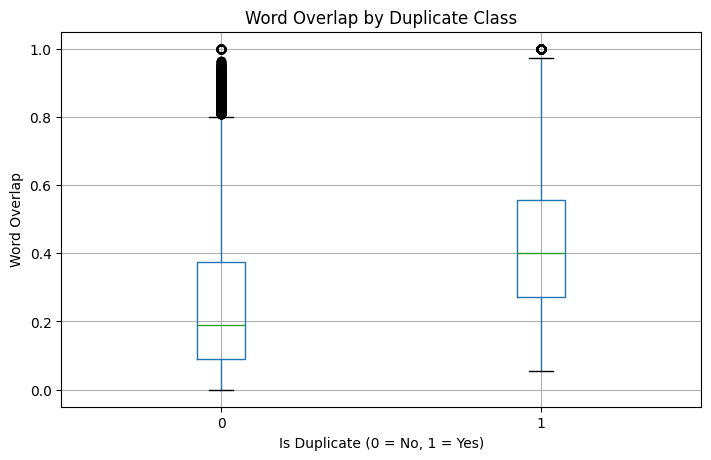

In [ ]:
import matplotlib.pyplot as plt

df.boxplot(
    column='word_overlap',
    by='is_duplicate',
    figsize=(8, 5)
)

plt.title('Word Overlap by Duplicate Class')
plt.suptitle('')
plt.xlabel('Is Duplicate (0 = No, 1 = Yes)')
plt.ylabel('Word Overlap')
plt.show()

In [ ]:
# Length of questions
df['q1_len'] = df['question1'].apply(lambda x: len(x))
df['q2_len'] = df['question2'].apply(lambda x: len(x))

# Word counts
df['q1_num_words'] = df['question1'].apply(lambda x: len(x.split()))
df['q2_num_words'] = df['question2'].apply(lambda x: len(x.split()))

print(df[['question1', 'q1_len', 'q1_num_words']].head())

                                                                      question1  \
0            What is the step by step guide to invest in share market in india?   
1                           What is the story of Kohinoor (Koh-i-Noor) Diamond?   
2     How can I increase the speed of my internet connection while using a VPN?   
3                            Why am I mentally very lonely? How can I solve it?   
4  Which one dissolve in water quikly sugar, salt, methane and carbon di oxide?   

   q1_len  q1_num_words  
0      66            14  
1      51             8  
2      73            14  
3      50            11  
4      76            13  


In [ ]:
 !pip install fuzzywuzzy python-Levenshtein


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.4/157.4 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 21.5 MB/s eta 0:00:00


In [ ]:
from fuzzywuzzy import fuzz

# Example: Adding fuzzy match features
df['fuzz_ratio'] = df.apply(lambda x: fuzz.ratio(str(x['question1']), str(x['question2'])), axis=1)
df['fuzz_partial_ratio'] = df.apply(lambda x: fuzz.partial_ratio(str(x['question1']), str(x['question2'])), axis=1)

In [ ]:
from fuzzywuzzy import fuzz

score = fuzz.ratio(
    "This is a question",
    "This is another question"
)

print("Similarity score:", score)

Similarity score: 86


In [ ]:
print(df.shape)
print(df.columns)

(404287, 17)
Index(['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate',
       'q1_length', 'q2_length', 'q1_words', 'q2_words', 'word_overlap',
       'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words', 'fuzz_ratio',
       'fuzz_partial_ratio'],
      dtype='object')


In [ ]:
print(df[['question1', 'question2']].isnull().sum())

question1    0
question2    0
dtype: int64


In [ ]:
sample_df = df.sample(
    10000,
    random_state=42
).copy()

In [ ]:
sample_df['fuzzy_ratio'] = sample_df.apply(
    lambda row: fuzz.ratio(
        row['question1'],
        row['question2']
    ),
    axis=1
)

print(sample_df[['question1', 'question2', 'fuzzy_ratio', 'is_duplicate']].head())

                                               question1  \
8067                  How do I play Pokémon GO in Korea?   
224279          Will a breathing treatment help a cough?   
252452     Is Kellyanne Conway annoying in your opinion?   
174039  How do you rate (1-10) and review Maruti Baleno?   
384863            What are some good books on marketing?   

                                                                                                                              question2  \
8067                                                                                                 How do I play Pokémon GO in China?   
224279                                                                  How can I help someone that is unconscious but still breathing?   
252452           Did Kellyanne Conway really imply that we should not pay attention to the words that come out of Donald Trump's mouth?   
174039  What career options does one have after completing a bachelor's degree (Dis

In [ ]:
sample_df.groupby('is_duplicate')['fuzzy_ratio'].mean()

,fuzzy_ratio
is_duplicate,
0,56.316627
1,70.149384


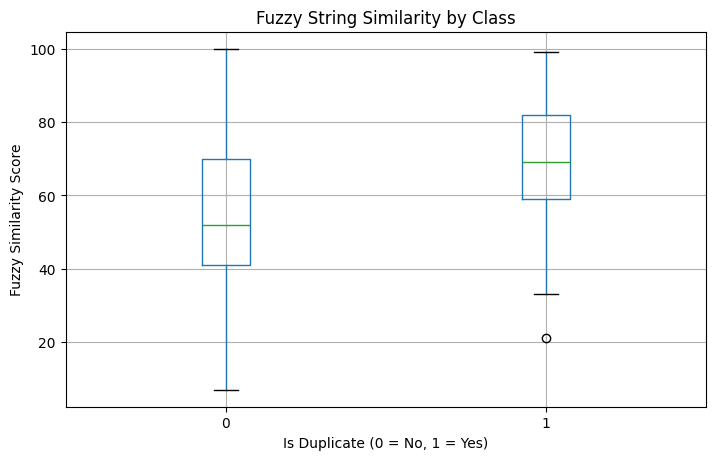

In [ ]:
import matplotlib.pyplot as plt

sample_df.boxplot(
    column='fuzzy_ratio',
    by='is_duplicate',
    figsize=(8, 5)
)

plt.title('Fuzzy String Similarity by Class')
plt.suptitle('')
plt.xlabel('Is Duplicate (0 = No, 1 = Yes)')
plt.ylabel('Fuzzy Similarity Score')
plt.show()

**Train Test Split**

In [ ]:
from sklearn.model_selection import train_test_split

X = df[['question1', 'question2']]
y = df['is_duplicate']

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 323429
Validation samples: 80858


In [ ]:
print("Training distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation distribution:")
print(y_val.value_counts())
print(y_val.value_counts(normalize=True) * 100)

Training distribution:
is_duplicate
0    204019
1    119410
Name: count, dtype: int64
is_duplicate
0    63.079996
1    36.920004
Name: proportion, dtype: float64

Validation distribution:
is_duplicate
0    51005
1    29853
Name: count, dtype: int64
is_duplicate
0    63.07972
1    36.92028
Name: proportion, dtype: float64


# **Create our first baseline**

# Create combined question text

## we're going to use TF-IDF + Logistic Regression.

In [ ]:
X_train_text = (
    X_train['question1'] + " [SEP] " + X_train['question2']
)

X_val_text = (
    X_val['question1'] + " [SEP] " + X_val['question2']
)

print(X_train_text.head())

33525     Has Ancient Chaldea been scientifically tested? [SEP] Has Ancient History been scientifically tested? Is it all real? Did it happen differently than we were told it did? Did it even happen at all?
369928                                                                                         What makes someone a good teacher? [SEP] What should be the first and most important quality of a good teacher?
176859                                                          Which is the best state for education for a international students in U.S? [SEP] What is the best state in the U.S for international students?
293960                                                                                 What are the most common ridge patterns in fingerprints? [SEP] Which ridge pattern is the least common in fingerprints?
182360                                                            Social History: When did Americans start giving birthday gifts? [SEP] Today is my nephew 6th birthday. Wha

**TF-IDF**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=100000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)

Training TF-IDF shape: (323429, 100000)
Validation TF-IDF shape: (80858, 100000)


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    n_jobs=-1
)

lr_model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = lr_model.predict(X_val_tfidf)
y_prob = lr_model.predict_proba(X_val_tfidf)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy :", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall   :", recall_score(y_val, y_pred))
print("F1 Score :", f1_score(y_val, y_pred))
print("ROC-AUC  :", roc_auc_score(y_val, y_prob))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

Accuracy : 0.783435157931188
Precision: 0.6870226694144744
Recall   : 0.7593541687602586
F1 Score : 0.7213798151124123
ROC-AUC  : 0.8629919471469081

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.80      0.82     51005
           1       0.69      0.76      0.72     29853

    accuracy                           0.78     80858
   macro avg       0.77      0.78      0.77     80858
weighted avg       0.79      0.78      0.79     80858



In [ ]:
!pip install -q sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu128
CUDA available: True


In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    'sentence-transformers/all-MiniLM-L6-v2'
)

print("Transformer model loaded successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Transformer model loaded successfully!


In [ ]:
test_questions = [
    "How can I learn Python?",
    "What is the best way to learn Python?",
    "What is the capital of India?"
]

test_embeddings = model.encode(
    test_questions,
    convert_to_tensor=True
)

print("Embedding shape:", test_embeddings.shape)

Embedding shape: torch.Size([3, 384])


In [ ]:
from sentence_transformers.util import cos_sim

similarity_1 = cos_sim(
    test_embeddings[0],
    test_embeddings[1]
)

similarity_2 = cos_sim(
    test_embeddings[0],
    test_embeddings[2]
)

print("Python question similarity:", similarity_1.item())
print("Python vs capital question:", similarity_2.item())

Python question similarity: 0.923626720905304
Python vs capital question: 0.02771596424281597


In [ ]:
transformer_sample = df[['question1', 'question2', 'is_duplicate']].sample(
    5000,
    random_state=42
).reset_index(drop=True)

transformer_sample.head()

,question1,question2,is_duplicate
0,How do I play Pokémon GO in Korea?,How do I play Pokémon GO in China?,0
1,Will a breathing treatment help a cough?,How can I help someone that is unconscious but still breathing?,0
2,Is Kellyanne Conway annoying in your opinion?,Did Kellyanne Conway really imply that we should not pay attention to the words that come out of Donald Trump's mouth?,0
3,How do you rate (1-10) and review Maruti Baleno?,What career options does one have after completing a bachelor's degree (Distance program in IGNOU) in tourism studies in India?,0
4,What are some good books on marketing?,What are some of the best books ever written about marketing?,1


In [ ]:
q1_embeddings = model.encode(
    transformer_sample['question1'].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Q1 embedding shape:", q1_embeddings.shape)

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Q1 embedding shape: (5000, 384)


In [ ]:
q2_embeddings = model.encode(
    transformer_sample['question2'].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Q2 embedding shape:", q2_embeddings.shape)

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Q2 embedding shape: (5000, 384)


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

semantic_similarity = []

for i in range(len(transformer_sample)):
    score = cosine_similarity(
        q1_embeddings[i].reshape(1, -1),
        q2_embeddings[i].reshape(1, -1)
    )[0][0]

    semantic_similarity.append(score)

transformer_sample['semantic_similarity'] = semantic_similarity

transformer_sample.head()

,question1,question2,is_duplicate,semantic_similarity
0,How do I play Pokémon GO in Korea?,How do I play Pokémon GO in China?,0,0.804451
1,Will a breathing treatment help a cough?,How can I help someone that is unconscious but still breathing?,0,0.455555
2,Is Kellyanne Conway annoying in your opinion?,Did Kellyanne Conway really imply that we should not pay attention to the words that come out of Donald Trump's mouth?,0,0.678740
3,How do you rate (1-10) and review Maruti Baleno?,What career options does one have after completing a bachelor's degree (Distance program in IGNOU) in tourism studies in India?,0,0.088534
4,What are some good books on marketing?,What are some of the best books ever written about marketing?,1,0.946184


In [ ]:
transformer_sample.groupby('is_duplicate')['semantic_similarity'].agg(
    ['mean', 'median', 'min', 'max']
)

,mean,median,min,max
is_duplicate,,,,
0,0.569715,0.614684,-0.124529,0.999364
1,0.866448,0.886507,0.438660,1.000000


In [ ]:
from sklearn.model_selection import train_test_split

X_similarity = transformer_sample[['semantic_similarity']]
y_similarity = transformer_sample['is_duplicate']

X_train_sim, X_val_sim, y_train_sim, y_val_sim = train_test_split(
    X_similarity,
    y_similarity,
    test_size=0.20,
    random_state=42,
    stratify=y_similarity
)

print("Training samples:", len(X_train_sim))
print("Validation samples:", len(X_val_sim))

Training samples: 4000
Validation samples: 1000


In [ ]:
from sklearn.linear_model import LogisticRegression

sim_model = LogisticRegression(
    class_weight='balanced',
    random_state=42
)

sim_model.fit(X_train_sim, y_train_sim)

LogisticRegression(class_weight='balanced', random_state=42)

In [ ]:
y_pred_sim = sim_model.predict(X_val_sim)
y_prob_sim = sim_model.predict_proba(X_val_sim)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_val_sim, y_pred_sim)
precision = precision_score(y_val_sim, y_pred_sim)
recall = recall_score(y_val_sim, y_pred_sim)
f1 = f1_score(y_val_sim, y_pred_sim)
roc_auc = roc_auc_score(y_val_sim, y_prob_sim)

print("Transformer Semantic Similarity Model")
print("--------------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_val_sim, y_pred_sim))

Transformer Semantic Similarity Model
--------------------------------------
Accuracy : 0.7650
Precision: 0.6331
Recall   : 0.8556
F1 Score : 0.7277
ROC-AUC  : 0.8628

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.71      0.79       633
           1       0.63      0.86      0.73       367

    accuracy                           0.77      1000
   macro avg       0.76      0.78      0.76      1000
weighted avg       0.80      0.77      0.77      1000



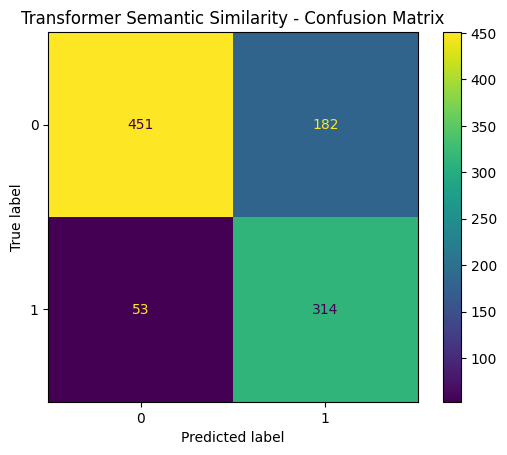

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val_sim,
    y_pred_sim
)

plt.title("Transformer Semantic Similarity - Confusion Matrix")
plt.show()

In [ ]:
import numpy as np

# Absolute difference between embeddings
embedding_diff = np.abs(q1_embeddings - q2_embeddings)

# Element-wise multiplication
embedding_product = q1_embeddings * q2_embeddings

# Cosine similarity as a single feature
similarity_feature = transformer_sample['semantic_similarity'].values.reshape(-1, 1)

# Combine all features
pair_features = np.hstack([
    similarity_feature,
    embedding_diff,
    embedding_product
])

print("Pair feature shape:", pair_features.shape)

Pair feature shape: (5000, 769)


In [ ]:
X_pair = pair_features
y_pair = transformer_sample['is_duplicate'].values

X_train_pair, X_val_pair, y_train_pair, y_val_pair = train_test_split(
    X_pair,
    y_pair,
    test_size=0.20,
    random_state=42,
    stratify=y_pair
)

print("Training:", X_train_pair.shape)
print("Validation:", X_val_pair.shape)

Training: (4000, 769)
Validation: (1000, 769)


In [ ]:
pair_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

pair_model.fit(X_train_pair, y_train_pair)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
y_pred_pair = pair_model.predict(X_val_pair)
y_prob_pair = pair_model.predict_proba(X_val_pair)[:, 1]

accuracy = accuracy_score(y_val_pair, y_pred_pair)
precision = precision_score(y_val_pair, y_pred_pair)
recall = recall_score(y_val_pair, y_pred_pair)
f1 = f1_score(y_val_pair, y_pred_pair)
roc_auc = roc_auc_score(y_val_pair, y_prob_pair)

print("Transformer Pair-Feature Model")
print("--------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_val_pair, y_pred_pair))

Transformer Pair-Feature Model
--------------------------------
Accuracy : 0.7730
Precision: 0.6483
Recall   : 0.8338
F1 Score : 0.7294
ROC-AUC  : 0.8657

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.74      0.80       633
           1       0.65      0.83      0.73       367

    accuracy                           0.77      1000
   macro avg       0.77      0.79      0.77      1000
weighted avg       0.80      0.77      0.78      1000



In [ ]:
error_analysis = transformer_sample.copy()

error_analysis['predicted'] = pair_model.predict(pair_features)

error_analysis['correct'] = (
    error_analysis['is_duplicate'] == error_analysis['predicted']
)

errors = error_analysis[
    error_analysis['correct'] == False
].copy()

print("Total errors:", len(errors))

errors[
    [
        'question1',
        'question2',
        'is_duplicate',
        'predicted',
        'semantic_similarity'
    ]
].head(20)

Total errors: 1098


,question1,question2,is_duplicate,predicted,semantic_similarity
0,How do I play Pokémon GO in Korea?,How do I play Pokémon GO in China?,0,1,0.804451
15,Is odd even scheme bad for Delhi?,Is ODD-EVEN scheme good for Delhi?,0,1,0.962559
16,Why do we worry so much when we know worrying doesn't bring any difference at all?,Why do we worry?,0,1,0.793596
27,How do I find Pokémon in Pokémon GO?,How do I find Pokémon Eggs in Pokémon GO?,0,1,0.850943
31,What kind of questions do you downvote on Quora?,What kind of questions should be downvoted on Quora?,0,1,0.918538
34,How can we control bad feelings?,How can I control my emotions and actions?,1,0,0.688414
46,What is an index fund? And how do I invest in it?,How do I invest in an index fund?,0,1,0.890038
47,What gift should I give to my girlfriend on her birthday?,Should I give a gift to my girlfriend on my birthday?,0,1,0.883209
57,How do you deal best with heartbreak?,What's the best way to deal with heartbreak?,0,1,0.956820
60,What is your opinion on Adolf Hitler's reputation?,What is your opinion of Adolf Hitler?,0,1,0.899410


In [ ]:
false_positives = errors[
    (errors['is_duplicate'] == 0) &
    (errors['predicted'] == 1)
]

false_negatives = errors[
    (errors['is_duplicate'] == 1) &
    (errors['predicted'] == 0)
]

print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

False Positives: 804
False Negatives: 294


In [ ]:
print("Total Transformer sample:", len(transformer_sample))
print("Total validation samples:", len(y_val_pair))
print("Total predictions:", len(y_pred_pair))

print("\nActual labels:")
print(pd.Series(y_val_pair).value_counts())

print("\nPredicted labels:")
print(pd.Series(y_pred_pair).value_counts())

print("\nConfusion matrix:")
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_val_pair, y_pred_pair))

Total Transformer sample: 5000
Total validation samples: 1000
Total predictions: 1000

Actual labels:
0    633
1    367
Name: count, dtype: int64

Predicted labels:
0    528
1    472
Name: count, dtype: int64

Confusion matrix:
[[467 166]
 [ 61 306]]


In [ ]:
print("Total pairs:", len(df))

print("Unique QID1:", df['qid1'].nunique())
print("Unique QID2:", df['qid2'].nunique())

all_qids = pd.concat([
    df['qid1'],
    df['qid2']
])

print("Unique questions:", all_qids.nunique())

Total pairs: 404287
Unique QID1: 290652
Unique QID2: 299362
Unique questions: 537929


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_val_pair, y_pred_pair)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nTotal validation samples:", tn + fp + fn + tp)

Confusion Matrix:
[[467 166]
 [ 61 306]]

TN: 467
FP: 166
FN: 61
TP: 306

Total validation samples: 1000


In [ ]:
transformer_40k = df[
    ['question1', 'question2', 'is_duplicate']
].sample(
    n=40000,
    random_state=42
).reset_index(drop=True)

print("40K dataset shape:", transformer_40k.shape)

print("\nClass distribution:")
print(transformer_40k['is_duplicate'].value_counts())

print("\nClass percentages:")
print(
    transformer_40k['is_duplicate']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

40K dataset shape: (40000, 3)

Class distribution:
is_duplicate
0    25143
1    14857
Name: count, dtype: int64

Class percentages:
is_duplicate
0    62.86
1    37.14
Name: proportion, dtype: float64


In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
for i, col in enumerate(df.columns):
    print(i, "->", col)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Shape: (404287, 17)

Columns:
0 -> id
1 -> qid1
2 -> qid2
3 -> question1
4 -> question2
5 -> is_duplicate
6 -> q1_length
7 -> q2_length
8 -> q1_words
9 -> q2_words
10 -> word_overlap
11 -> q1_len
12 -> q2_len
13 -> q1_num_words
14 -> q2_num_words
15 -> fuzz_ratio
16 -> fuzz_partial_ratio

First 5 rows:


,id,qid1,qid2,question1,question2,is_duplicate,q1_length,q2_length,q1_words,q2_words,word_overlap,q1_len,q2_len,q1_num_words,q2_num_words,fuzz_ratio,fuzz_partial_ratio
0,0,1,2,What is the step by step guide to invest in share market in india?,What is the step by step guide to invest in share market?,0,66.0,57.0,14.0,12.0,0.769231,66,57,14,12,93,98
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Diamond?,What would happen if the Indian government stole the Kohinoor (Koh-i-Noor) diamond back?,0,51.0,88.0,8.0,13.0,0.250000,51,88,8,13,65,73
2,2,5,6,How can I increase the speed of my internet connection while using a VPN?,How can Internet speed be increased by hacking through DNS?,0,73.0,59.0,14.0,10.0,0.200000,73,59,14,10,55,53
3,3,7,8,Why am I mentally very lonely? How can I solve it?,"Find the remainder when [math]23^{24}[/math] is divided by 24,23?",0,50.0,65.0,11.0,9.0,0.000000,50,65,11,9,28,30
4,4,9,10,"Which one dissolve in water quikly sugar, salt, methane and carbon di oxide?",Which fish would survive in salt water?,0,76.0,39.0,13.0,7.0,0.111111,76,39,13,7,45,54



Data types:
id                      int64
qid1                    int64
qid2                    int64
question1              object
question2              object
is_duplicate            int64
q1_length             float64
q2_length             float64
q1_words              float64
q2_words              float64
word_overlap          float64
q1_len                  int64
q2_len                  int64
q1_num_words            int64
q2_num_words            int64
fuzz_ratio              int64
fuzz_partial_ratio      int64
dtype: object


In [ ]:
print(df.shape)
print(df.columns.tolist())

(404287, 17)
['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate', 'q1_length', 'q2_length', 'q1_words', 'q2_words', 'word_overlap', 'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words', 'fuzz_ratio', 'fuzz_partial_ratio']


In [ ]:
model_df = df[[
    "question1",
    "question2",
    "is_duplicate",
    "q1_len",
    "q2_len",
    "q1_num_words",
    "q2_num_words",
    "word_overlap",
    "fuzz_ratio",
    "fuzz_partial_ratio"
]].copy()

print("Shape:", model_df.shape)
display(model_df.head())


Shape: (404287, 10)


,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_overlap,fuzz_ratio,fuzz_partial_ratio
0,What is the step by step guide to invest in share market in india?,What is the step by step guide to invest in share market?,0,66,57,14,12,0.769231,93,98
1,What is the story of Kohinoor (Koh-i-Noor) Diamond?,What would happen if the Indian government stole the Kohinoor (Koh-i-Noor) diamond back?,0,51,88,8,13,0.250000,65,73
2,How can I increase the speed of my internet connection while using a VPN?,How can Internet speed be increased by hacking through DNS?,0,73,59,14,10,0.200000,55,53
3,Why am I mentally very lonely? How can I solve it?,"Find the remainder when [math]23^{24}[/math] is divided by 24,23?",0,50,65,11,9,0.000000,28,30
4,"Which one dissolve in water quikly sugar, salt, methane and carbon di oxide?",Which fish would survive in salt water?,0,76,39,13,7,0.111111,45,54


In [ ]:
print(model_df.isnull().sum())

question1             0
question2             0
is_duplicate          0
q1_len                0
q2_len                0
q1_num_words          0
q2_num_words          0
word_overlap          0
fuzz_ratio            0
fuzz_partial_ratio    0
dtype: int64


In [ ]:
print(model_df["is_duplicate"].value_counts())

print("\nPercentage:")
print(
    model_df["is_duplicate"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

is_duplicate
0    255024
1    149263
Name: count, dtype: int64

Percentage:
is_duplicate
0    63.08
1    36.92
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    model_df,
    test_size=0.20,
    random_state=42,
    stratify=model_df["is_duplicate"]
)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

Train shape: (323429, 10)
Test shape : (80858, 10)


In [ ]:
print("TRAIN distribution:")
print(train_df["is_duplicate"].value_counts())
print(train_df["is_duplicate"].value_counts(normalize=True).mul(100).round(2))

print("\nTEST distribution:")
print(test_df["is_duplicate"].value_counts())
print(test_df["is_duplicate"].value_counts(normalize=True).mul(100).round(2))

TRAIN distribution:
is_duplicate
0    204019
1    119410
Name: count, dtype: int64
is_duplicate
0    63.08
1    36.92
Name: proportion, dtype: float64

TEST distribution:
is_duplicate
0    51005
1    29853
Name: count, dtype: int64
is_duplicate
0    63.08
1    36.92
Name: proportion, dtype: float64


In [ ]:
feature_cols = [
    "q1_len",
    "q2_len",
    "q1_num_words",
    "q2_num_words",
    "word_overlap",
    "fuzz_ratio",
    "fuzz_partial_ratio"
]

X_train = train_df[feature_cols]
y_train = train_df["is_duplicate"]

X_test = test_df[feature_cols]
y_test = test_df["is_duplicate"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (323429, 7)
y_train: (323429,)
X_test : (80858, 7)
y_test : (80858,)


In [ ]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [ ]:
y_pred = baseline_model.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.6693
Precision: 0.5415
Recall   : 0.6805
F1 Score : 0.6031

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.66      0.72     51005
           1       0.54      0.68      0.60     29853

    accuracy                           0.67     80858
   macro avg       0.66      0.67      0.66     80858
weighted avg       0.69      0.67      0.67     80858



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[33806 17199]
 [ 9537 20316]]


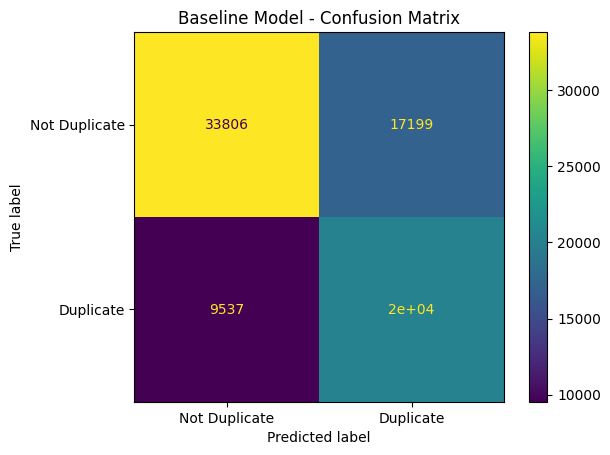

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Duplicate", "Duplicate"]
).plot()

plt.title("Baseline Model - Confusion Matrix")
plt.show()

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: True
Tesla T4


In [ ]:
train_q1 = train_df["question1"].fillna("")
train_q2 = train_df["question2"].fillna("")

test_q1 = test_df["question1"].fillna("")
test_q2 = test_df["question2"].fillna("")

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=100000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

all_train_questions = pd.concat(
    [train_q1, train_q2],
    axis=0
)

tfidf.fit(all_train_questions)

print("Vocabulary size:", len(tfidf.vocabulary_))

Vocabulary size: 100000


In [ ]:
q1_train_tfidf = tfidf.transform(train_q1)
q2_train_tfidf = tfidf.transform(train_q2)

q1_test_tfidf = tfidf.transform(test_q1)
q2_test_tfidf = tfidf.transform(test_q2)

print("Q1 train:", q1_train_tfidf.shape)
print("Q2 train:", q2_train_tfidf.shape)

Q1 train: (323429, 100000)
Q2 train: (323429, 100000)


In [ ]:
import numpy as np

def pairwise_cosine_similarity(A, B, batch_size=5000):
    similarities = []

    for start in range(0, A.shape[0], batch_size):
        end = min(start + batch_size, A.shape[0])

        A_batch = A[start:end]
        B_batch = B[start:end]

        # Similarity between corresponding rows only
        sim = A_batch.multiply(B_batch).sum(axis=1)

        similarities.extend(np.asarray(sim).ravel())

        if end % 50000 == 0 or end == A.shape[0]:
            print(f"Processed {end:,} / {A.shape[0]:,}")

    return np.array(similarities)

In [ ]:
print(q1_train_tfidf.shape)
print(q2_train_tfidf.shape)
print(q1_test_tfidf.shape)
print(q2_test_tfidf.shape)

(323429, 100000)
(323429, 100000)
(80858, 100000)
(80858, 100000)


In [ ]:
train_similarity = pairwise_cosine_similarity(
    q1_train_tfidf,
    q2_train_tfidf
)

print("Train similarity shape:", train_similarity.shape)
print("First 10 similarities:", train_similarity[:10])

Processed 50,000 / 323,429
Processed 100,000 / 323,429
Processed 150,000 / 323,429
Processed 200,000 / 323,429
Processed 250,000 / 323,429
Processed 300,000 / 323,429
Processed 323,429 / 323,429
Train similarity shape: (323429,)
First 10 similarities: [0.37851058 0.28837571 0.56179091 0.42885773 0.06365312 0.1703251
 0.18324608 0.13677062 0.09588373 0.18909817]


In [ ]:
test_similarity = pairwise_cosine_similarity(
    q1_test_tfidf,
    q2_test_tfidf
)

print("Test similarity shape:", test_similarity.shape)
print("First 10 similarities:", test_similarity[:10])

Processed 50,000 / 80,858
Processed 80,858 / 80,858
Test similarity shape: (80858,)
First 10 similarities: [0.90366624 0.47653307 0.2909065  0.48612056 0.2837318  0.63112179
 0.35238005 0.21909669 0.45829554 0.67327541]


In [ ]:
print("Train similarity:")
print("Min:", train_similarity.min())
print("Max:", train_similarity.max())
print("Mean:", train_similarity.mean())

print("\nTest similarity:")
print("Min:", test_similarity.min())
print("Max:", test_similarity.max())
print("Mean:", test_similarity.mean())

Train similarity:
Min: 0.0
Max: 1.0000000000000007
Mean: 0.3795579193271032

Test similarity:
Min: 0.0
Max: 1.0000000000000007
Mean: 0.3790847203392308


In [ ]:
print("Train similarity:")
print("Min:", train_similarity.min())
print("Max:", train_similarity.max())
print("Mean:", train_similarity.mean())

print("\nTest similarity:")
print("Min:", test_similarity.min())
print("Max:", test_similarity.max())
print("Mean:", test_similarity.mean())

Train similarity:
Min: 0.0
Max: 1.0000000000000007
Mean: 0.3795579193271032

Test similarity:
Min: 0.0
Max: 1.0000000000000007
Mean: 0.3790847203392308


In [ ]:
X_train_tfidf = np.column_stack([
    train_df["q1_len"].values,
    train_df["q2_len"].values,
    train_df["q1_num_words"].values,
    train_df["q2_num_words"].values,
    train_df["word_overlap"].values,
    train_df["fuzz_ratio"].values,
    train_df["fuzz_partial_ratio"].values,
    train_similarity
])

X_test_tfidf = np.column_stack([
    test_df["q1_len"].values,
    test_df["q2_len"].values,
    test_df["q1_num_words"].values,
    test_df["q2_num_words"].values,
    test_df["word_overlap"].values,
    test_df["fuzz_ratio"].values,
    test_df["fuzz_partial_ratio"].values,
    test_similarity
])

print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_test_tfidf shape:", X_test_tfidf.shape)

X_train_tfidf shape: (323429, 8)
X_test_tfidf shape: (80858, 8)


In [ ]:
from sklearn.linear_model import LogisticRegression

tfidf_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

tfidf_model.fit(
    X_train_tfidf,
    y_train
)

print("TF-IDF model training completed!")

TF-IDF model training completed!


In [ ]:
y_pred_tfidf = tfidf_model.predict(X_test_tfidf)

print("Predictions completed!")
print("Prediction shape:", y_pred_tfidf.shape)

Predictions completed!
Prediction shape: (80858,)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy_tfidf = accuracy_score(y_test, y_pred_tfidf)
precision_tfidf = precision_score(y_test, y_pred_tfidf)
recall_tfidf = recall_score(y_test, y_pred_tfidf)
f1_tfidf = f1_score(y_test, y_pred_tfidf)

print("TF-IDF + Engineered Features Results")
print("--------------------------------------")
print(f"Accuracy : {accuracy_tfidf:.4f}")
print(f"Precision: {precision_tfidf:.4f}")
print(f"Recall   : {recall_tfidf:.4f}")
print(f"F1 Score : {f1_tfidf:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tfidf))

TF-IDF + Engineered Features Results
--------------------------------------
Accuracy : 0.6762
Precision: 0.5488
Recall   : 0.6923
F1 Score : 0.6122

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.67      0.72     51005
           1       0.55      0.69      0.61     29853

    accuracy                           0.68     80858
   macro avg       0.67      0.68      0.67     80858
weighted avg       0.70      0.68      0.68     80858



Confusion Matrix:
[[34013 16992]
 [ 9186 20667]]


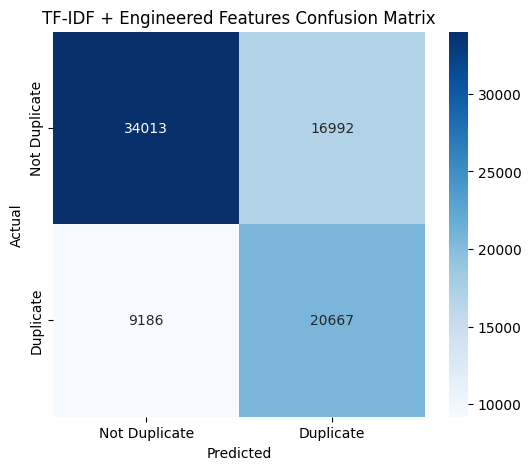

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)

print("Confusion Matrix:")
print(cm_tfidf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_tfidf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Duplicate", "Duplicate"],
    yticklabels=["Not Duplicate", "Duplicate"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("TF-IDF + Engineered Features Confusion Matrix")
plt.show()

In [ ]:
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"

semantic_model = SentenceTransformer(
    "all-MiniLM-L6-v2",
    device=device
)

print("Model loaded on:", device)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded on: cuda


In [ ]:
# Prepare all questions

all_q1 = model_df["question1"].fillna("").astype(str).tolist()
all_q2 = model_df["question2"].fillna("").astype(str).tolist()

print("Total question pairs:", len(all_q1))
print("Q1 count:", len(all_q1))
print("Q2 count:", len(all_q2))

Total question pairs: 404287
Q1 count: 404287
Q2 count: 404287


In [ ]:
import numpy as np
import torch

def generate_embeddings(texts, model, batch_size=256):
    embeddings = []

    for start in range(0, len(texts), batch_size):
        end = min(start + batch_size, len(texts))

        batch_texts = texts[start:end]

        batch_embeddings = model.encode(
            batch_texts,
            batch_size=batch_size,
            show_progress_bar=False,
            convert_to_numpy=True,
            normalize_embeddings=True
        )

        embeddings.append(batch_embeddings)

        if end % 20000 == 0 or end == len(texts):
            print(f"Processed {end:,} / {len(texts):,}")

    return np.vstack(embeddings)

In [ ]:
q1_embeddings = generate_embeddings(
    all_q1,
    semantic_model,
    batch_size=256
)

print("Q1 embeddings shape:", q1_embeddings.shape)

Processed 160,000 / 404,287
Processed 320,000 / 404,287
Processed 404,287 / 404,287
Q1 embeddings shape: (404287, 384)


In [ ]:
q2_embeddings = generate_embeddings(
    all_q2,
    semantic_model,
    batch_size=256
)

print("Q2 embeddings shape:", q2_embeddings.shape)

Processed 160,000 / 404,287
Processed 320,000 / 404,287
Processed 404,287 / 404,287
Q2 embeddings shape: (404287, 384)


In [ ]:
# Cosine similarity for corresponding question pairs
semantic_similarity = np.sum(
    q1_embeddings * q2_embeddings,
    axis=1
)

print("Semantic similarity shape:", semantic_similarity.shape)
print("First 10 similarities:", semantic_similarity[:10])
print("Min similarity:", semantic_similarity.min())
print("Max similarity:", semantic_similarity.max())
print("Mean similarity:", semantic_similarity.mean())

Semantic similarity shape: (404287,)
First 10 similarities: [0.9122765  0.65514123 0.5155606  0.10402153 0.3253477  0.837468
 0.05169931 0.9369588  0.32272768 0.7325238 ]
Min similarity: -0.26585367
Max similarity: 1.0000002
Mean similarity: 0.67273575


In [ ]:
# Reset indices so row positions match the semantic similarity array

model_df = model_df.reset_index(drop=True)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Model DF:", model_df.shape)
print("Train DF:", train_df.shape)
print("Test DF:", test_df.shape)

Model DF: (404287, 10)
Train DF: (323429, 10)
Test DF: (80858, 10)


In [ ]:
train_q1_embeddings = generate_embeddings(
    train_df["question1"].fillna("").astype(str).tolist(),
    semantic_model,
    batch_size=256
)

train_q2_embeddings = generate_embeddings(
    train_df["question2"].fillna("").astype(str).tolist(),
    semantic_model,
    batch_size=256
)

print("Train Q1:", train_q1_embeddings.shape)
print("Train Q2:", train_q2_embeddings.shape)

Processed 160,000 / 323,429
Processed 320,000 / 323,429
Processed 323,429 / 323,429
Processed 160,000 / 323,429
Processed 320,000 / 323,429
Processed 323,429 / 323,429
Train Q1: (323429, 384)
Train Q2: (323429, 384)


In [ ]:
test_q1_embeddings = generate_embeddings(
    test_df["question1"].fillna("").astype(str).tolist(),
    semantic_model,
    batch_size=256
)

test_q2_embeddings = generate_embeddings(
    test_df["question2"].fillna("").astype(str).tolist(),
    semantic_model,
    batch_size=256
)

print("Test Q1:", test_q1_embeddings.shape)
print("Test Q2:", test_q2_embeddings.shape)

Processed 80,858 / 80,858
Processed 80,858 / 80,858
Test Q1: (80858, 384)
Test Q2: (80858, 384)


In [ ]:
train_semantic_similarity = np.sum(
    train_q1_embeddings * train_q2_embeddings,
    axis=1
)

print("Train semantic similarity:", train_semantic_similarity.shape)
print("Train mean similarity:", train_semantic_similarity.mean())

Train semantic similarity: (323429,)
Train mean similarity: 0.67270756


In [ ]:
test_semantic_similarity = np.sum(
    test_q1_embeddings * test_q2_embeddings,
    axis=1
)

print("Test semantic similarity:", test_semantic_similarity.shape)
print("Test mean similarity:", test_semantic_similarity.mean())

Test semantic similarity: (80858,)
Test mean similarity: 0.6728486


In [ ]:
X_train_semantic = np.column_stack([
    train_df["q1_len"].values,
    train_df["q2_len"].values,
    train_df["q1_num_words"].values,
    train_df["q2_num_words"].values,
    train_df["word_overlap"].values,
    train_df["fuzz_ratio"].values,
    train_df["fuzz_partial_ratio"].values,
    train_semantic_similarity
])

X_test_semantic = np.column_stack([
    test_df["q1_len"].values,
    test_df["q2_len"].values,
    test_df["q1_num_words"].values,
    test_df["q2_num_words"].values,
    test_df["word_overlap"].values,
    test_df["fuzz_ratio"].values,
    test_df["fuzz_partial_ratio"].values,
    test_semantic_similarity
])

print("X_train_semantic shape:", X_train_semantic.shape)
print("X_test_semantic shape:", X_test_semantic.shape)

X_train_semantic shape: (323429, 8)
X_test_semantic shape: (80858, 8)


In [ ]:
from sklearn.linear_model import LogisticRegression

semantic_classifier = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

semantic_classifier.fit(
    X_train_semantic,
    y_train
)

print("Semantic model training completed!")

Semantic model training completed!


In [ ]:
y_pred_semantic = semantic_classifier.predict(X_test_semantic)

print("Prediction shape:", y_pred_semantic.shape)

Prediction shape: (80858,)


In [ ]:
accuracy_semantic = accuracy_score(y_test, y_pred_semantic)
precision_semantic = precision_score(y_test, y_pred_semantic)
recall_semantic = recall_score(y_test, y_pred_semantic)
f1_semantic = f1_score(y_test, y_pred_semantic)

print("Semantic Similarity + Engineered Features Results")
print("--------------------------------------------------")
print(f"Accuracy : {accuracy_semantic:.4f}")
print(f"Precision: {precision_semantic:.4f}")
print(f"Recall   : {recall_semantic:.4f}")
print(f"F1 Score : {f1_semantic:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_semantic))

Semantic Similarity + Engineered Features Results
--------------------------------------------------
Accuracy : 0.7842
Precision: 0.6594
Recall   : 0.8593
F1 Score : 0.7462

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.81     51005
           1       0.66      0.86      0.75     29853

    accuracy                           0.78     80858
   macro avg       0.78      0.80      0.78     80858
weighted avg       0.81      0.78      0.79     80858



Semantic Model Confusion Matrix:
[[37752 13253]
 [ 4199 25654]]


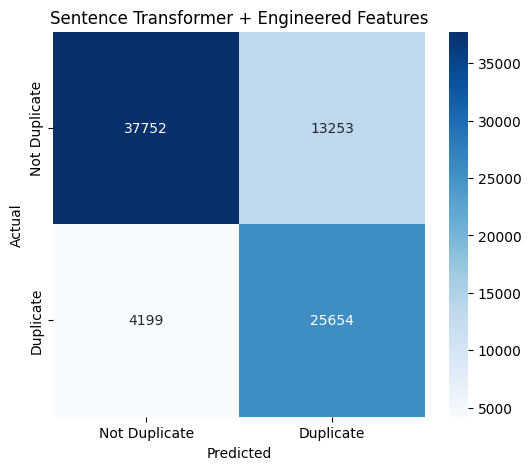

In [ ]:
cm_semantic = confusion_matrix(
    y_test,
    y_pred_semantic
)

print("Semantic Model Confusion Matrix:")
print(cm_semantic)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_semantic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Duplicate", "Duplicate"],
    yticklabels=["Not Duplicate", "Duplicate"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Sentence Transformer + Engineered Features")

plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Engineered Features + Logistic Regression",
        "TF-IDF + Engineered Features",
        "Sentence Transformer + Engineered Features"
    ],
    "Accuracy": [
        accuracy,
        accuracy_tfidf,
        accuracy_semantic
    ],
    "Precision": [
        precision,
        precision_tfidf,
        precision_semantic
    ],
    "Recall": [
        recall,
        recall_tfidf,
        recall_semantic
    ],
    "F1 Score": [
        f1,
        f1_tfidf,
        f1_semantic
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Engineered Features + Logistic Regression,0.669346,0.541543,0.680535,0.603135
1,TF-IDF + Engineered Features,0.676247,0.548793,0.692292,0.612247
2,Sentence Transformer + Engineered Features,0.784165,0.659367,0.859344,0.746190


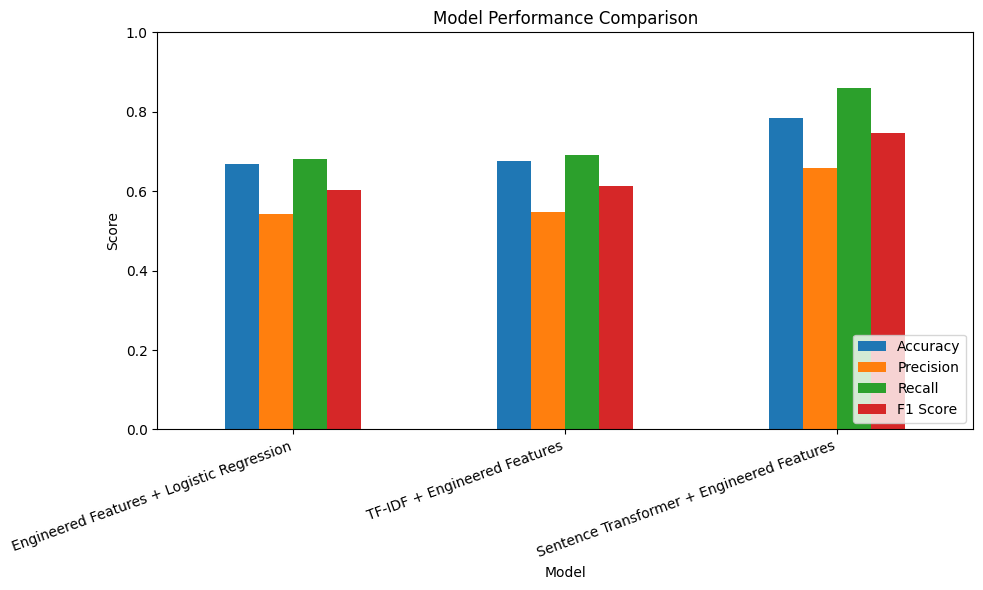

In [ ]:
results.set_index("Model")[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

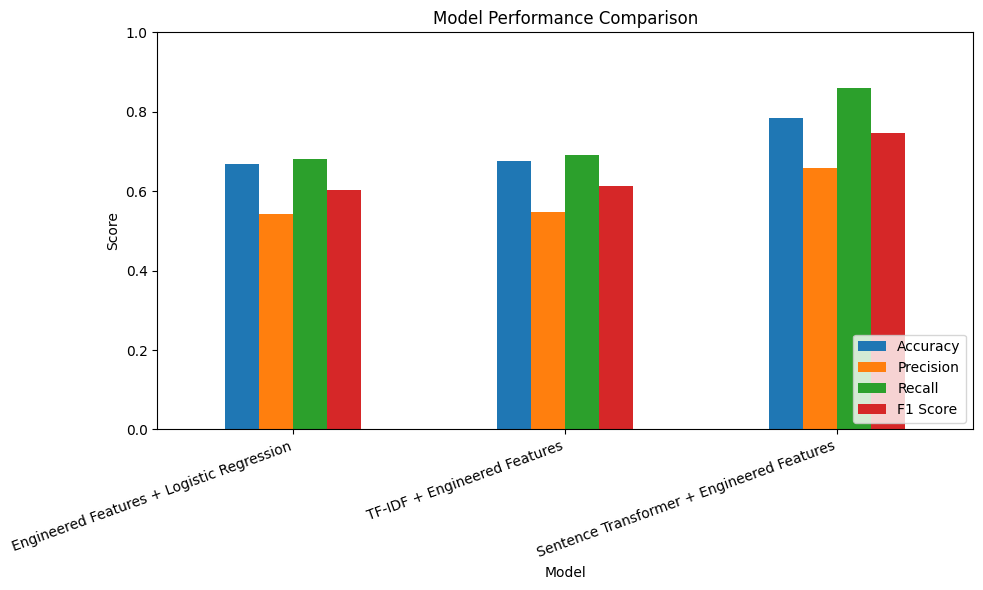

In [ ]:
results.set_index("Model")[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
results.to_csv(
    "duplicate_question_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [ ]:
error_df = test_df[[
    "question1",
    "question2",
    "is_duplicate"
]].copy()

error_df["predicted"] = y_pred_semantic

error_df["error_type"] = "Correct"

error_df.loc[
    (error_df["is_duplicate"] == 1) &
    (error_df["predicted"] == 0),
    "error_type"
] = "False Negative"

error_df.loc[
    (error_df["is_duplicate"] == 0) &
    (error_df["predicted"] == 1),
    "error_type"
] = "False Positive"

print(error_df["error_type"].value_counts())

error_type
Correct           63406
False Positive    13253
False Negative     4199
Name: count, dtype: int64


In [ ]:
false_positive_df = error_df[
    error_df["error_type"] == "False Positive"
]

false_negative_df = error_df[
    error_df["error_type"] == "False Negative"
]

print("FALSE POSITIVE EXAMPLES")
display(
    false_positive_df[
        ["question1", "question2", "is_duplicate", "predicted"]
    ].head(10)
)

print("\nFALSE NEGATIVE EXAMPLES")
display(
    false_negative_df[
        ["question1", "question2", "is_duplicate", "predicted"]
    ].head(10)
)

FALSE POSITIVE EXAMPLES


,question1,question2,is_duplicate,predicted
0,What are some tips on making it through the job interview process at Lifetime Brands?,What are some tips on making it through the job interview process at L Brands?,0,1
3,What is the scope after doing M.Tech. from IIT?,What are the opportunities after doing M.Tech from good IITs?,0,1
5,What is value added tax? What is the difference between VAT and sales tax?,What is VAT (Value Added Tax)?,0,1
6,Which phone should I buy Moto Z Play or OnePlus 3T?,Should I buy OnePlus 3T or should I go for any other phones of the same price range?,0,1
7,Which are the best apps to have in your Android after rooting?,What are the Best rooted apps for Android?,0,1
12,How is proprietary software developed?,What is proprietary software?,0,1
13,"How can I make a billion (1,000 million) dollars?","What are some ways to make 1,000 dollars?",0,1
14,Is torrents ban in India?,Is YIFY torrent banned in India?,0,1
16,Why do foot worship videos turn me on but doing it doesn't?,Why do foot worship videos turn me on but doing it doesn't? :/,0,1
38,How can I get Android Nougat?,What is Android Nougat?,0,1



FALSE NEGATIVE EXAMPLES


,question1,question2,is_duplicate,predicted
2,Why can't I beat my porn addiction?,What is the most effective way to break a porn addiction?,1,0
18,What should I do when all group members suddenly start making fun of me?,How should I behave when all group members suddenly stops talking with me?,1,0
50,What is digital marketing?What are the basics of Digital Marketing?What is digital marketing strategy?Who needs digital marketing services?,What are the basics of Digital Marketing?,1,0
52,What's the best way to learn general programming?,What are best resources to learn programming for a beginner?,1,0
55,Which are the best books to learn C++?,"I am supposed to do a Biotechnology related project at IIT GUWAHATI. I need to learn C++, what are the best books or sources to learn?",1,0
62,Are there any conservative outposts on Quora?,Do right-wingers exist on Quora?,1,0
64,Do keywords and meta tags still important and matters in SEO?,Is keyword ranking still important in SEO?,1,0
91,What is (was) the most peaceful nation in history?,What was the most peaceful society and closest to nature in history?,1,0
93,Will demonetisation really curb black money?,Will demonetisation really help?,1,0
103,How should I go about getting funding for my idea?,How do I get to just tell investors about my startup idea?,1,0


In [ ]:
false_positive_df = error_df[
    error_df["error_type"] == "False Positive"
]

false_negative_df = error_df[
    error_df["error_type"] == "False Negative"
]

print("FALSE POSITIVE EXAMPLES")
display(
    false_positive_df[
        ["question1", "question2", "is_duplicate", "predicted"]
    ].head(10)
)

print("\nFALSE NEGATIVE EXAMPLES")
display(
    false_negative_df[
        ["question1", "question2", "is_duplicate", "predicted"]
    ].head(10)
)

FALSE POSITIVE EXAMPLES


,question1,question2,is_duplicate,predicted
0,What are some tips on making it through the job interview process at Lifetime Brands?,What are some tips on making it through the job interview process at L Brands?,0,1
3,What is the scope after doing M.Tech. from IIT?,What are the opportunities after doing M.Tech from good IITs?,0,1
5,What is value added tax? What is the difference between VAT and sales tax?,What is VAT (Value Added Tax)?,0,1
6,Which phone should I buy Moto Z Play or OnePlus 3T?,Should I buy OnePlus 3T or should I go for any other phones of the same price range?,0,1
7,Which are the best apps to have in your Android after rooting?,What are the Best rooted apps for Android?,0,1
12,How is proprietary software developed?,What is proprietary software?,0,1
13,"How can I make a billion (1,000 million) dollars?","What are some ways to make 1,000 dollars?",0,1
14,Is torrents ban in India?,Is YIFY torrent banned in India?,0,1
16,Why do foot worship videos turn me on but doing it doesn't?,Why do foot worship videos turn me on but doing it doesn't? :/,0,1
38,How can I get Android Nougat?,What is Android Nougat?,0,1



FALSE NEGATIVE EXAMPLES


,question1,question2,is_duplicate,predicted
2,Why can't I beat my porn addiction?,What is the most effective way to break a porn addiction?,1,0
18,What should I do when all group members suddenly start making fun of me?,How should I behave when all group members suddenly stops talking with me?,1,0
50,What is digital marketing?What are the basics of Digital Marketing?What is digital marketing strategy?Who needs digital marketing services?,What are the basics of Digital Marketing?,1,0
52,What's the best way to learn general programming?,What are best resources to learn programming for a beginner?,1,0
55,Which are the best books to learn C++?,"I am supposed to do a Biotechnology related project at IIT GUWAHATI. I need to learn C++, what are the best books or sources to learn?",1,0
62,Are there any conservative outposts on Quora?,Do right-wingers exist on Quora?,1,0
64,Do keywords and meta tags still important and matters in SEO?,Is keyword ranking still important in SEO?,1,0
91,What is (was) the most peaceful nation in history?,What was the most peaceful society and closest to nature in history?,1,0
93,Will demonetisation really curb black money?,Will demonetisation really help?,1,0
103,How should I go about getting funding for my idea?,How do I get to just tell investors about my startup idea?,1,0


In [ ]:
# Analyze semantic similarity by actual class

similarity_analysis = pd.DataFrame({
    "is_duplicate": y_test.values,
    "semantic_similarity": test_semantic_similarity
})

print("Non-Duplicate Questions (0):")
print(
    similarity_analysis[
        similarity_analysis["is_duplicate"] == 0
    ]["semantic_similarity"].describe()
)

print("\nDuplicate Questions (1):")
print(
    similarity_analysis[
        similarity_analysis["is_duplicate"] == 1
    ]["semantic_similarity"].describe()
)

Non-Duplicate Questions (0):
count    51005.000000
mean         0.560561
std          0.271286
min         -0.198441
25%          0.399764
50%          0.610910
75%          0.776565
max          1.000000
Name: semantic_similarity, dtype: float64

Duplicate Questions (1):
count    29853.000000
mean         0.864695
std          0.095315
min          0.269612
25%          0.806766
50%          0.881454
75%          0.939818
max          1.000000
Name: semantic_similarity, dtype: float64


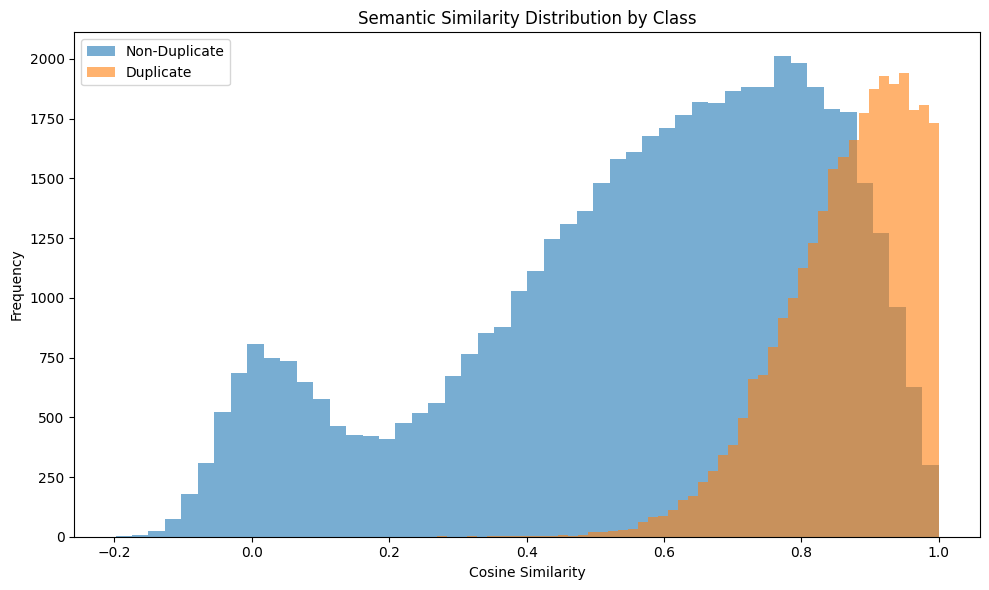

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    similarity_analysis[
        similarity_analysis["is_duplicate"] == 0
    ]["semantic_similarity"],
    bins=50,
    alpha=0.6,
    label="Non-Duplicate"
)

plt.hist(
    similarity_analysis[
        similarity_analysis["is_duplicate"] == 1
    ]["semantic_similarity"],
    bins=50,
    alpha=0.6,
    label="Duplicate"
)

plt.title("Semantic Similarity Distribution by Class")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Get probability of the pair being a duplicate
y_prob_semantic = semantic_classifier.predict_proba(
    X_test_semantic
)[:, 1]

print("Number of probabilities:", len(y_prob_semantic))
print("Minimum probability:", y_prob_semantic.min())
print("Maximum probability:", y_prob_semantic.max())
print("Mean probability:", y_prob_semantic.mean())

Number of probabilities: 80858
Minimum probability: 8.965575302816455e-06
Maximum probability: 0.97305039929556
Mean probability: 0.4413246039091382


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_semantic >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1 Score": f1_score(y_test, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.30,0.739853,0.592366,0.947174,0.728885
1,0.35,0.754359,0.609726,0.929856,0.736508
2,0.40,0.765972,0.625846,0.910394,0.741768
3,0.45,0.775693,0.642171,0.886343,0.744754
4,0.50,0.784165,0.659367,0.859344,0.746190
5,0.55,0.788951,0.675467,0.824507,0.742582
6,0.60,0.792340,0.693913,0.782869,0.735712
7,0.65,0.792488,0.713809,0.731049,0.722326
8,0.70,0.789433,0.736181,0.669648,0.701340


In [ ]:
final_results = results.copy()

final_results["Accuracy"] = (
    final_results["Accuracy"] * 100
).round(2)

final_results["Precision"] = (
    final_results["Precision"] * 100
).round(2)

final_results["Recall"] = (
    final_results["Recall"] * 100
).round(2)

final_results["F1 Score"] = (
    final_results["F1 Score"] * 100
).round(2)

display(final_results)

,Model,Accuracy,Precision,Recall,F1 Score
0,Engineered Features + Logistic Regression,66.93,54.15,68.05,60.31
1,TF-IDF + Engineered Features,67.62,54.88,69.23,61.22
2,Sentence Transformer + Engineered Features,78.42,65.94,85.93,74.62


In [ ]:
baseline = results.iloc[0]
semantic_model = results.iloc[2]

print("Improvement from Baseline to Sentence Transformer")
print("-" * 50)

print(
    f"Accuracy: +{(semantic_model['Accuracy'] - baseline['Accuracy']) * 100:.2f} percentage points"
)

print(
    f"Precision: +{(semantic_model['Precision'] - baseline['Precision']) * 100:.2f} percentage points"
)

print(
    f"Recall: +{(semantic_model['Recall'] - baseline['Recall']) * 100:.2f} percentage points"
)

print(
    f"F1 Score: +{(semantic_model['F1 Score'] - baseline['F1 Score']) * 100:.2f} percentage points"
)

Improvement from Baseline to Sentence Transformer
--------------------------------------------------
Accuracy: +11.48 percentage points
Precision: +11.78 percentage points
Recall: +17.88 percentage points
F1 Score: +14.31 percentage points


## Final Observations

- The baseline model using engineered linguistic features achieved an accuracy of 66.93% and an F1 score of 60.31%.
- Adding TF-IDF features produced a small improvement, increasing accuracy to 67.62% and F1 score to 61.22%.
- The Sentence Transformer approach significantly improved performance, achieving 78.42% accuracy and an F1 score of 74.62%.
- Compared with the baseline, the Sentence Transformer model improved accuracy by 11.48 percentage points and F1 score by 14.31 percentage points.
- Recall increased by 17.88 percentage points, reaching 85.93%, indicating that the semantic model identified a larger proportion of actual duplicate-question pairs.
- The results indicate that semantic embeddings captured similarities in question meaning more effectively than traditional lexical features alone.
- However, the model still produced false positives, showing that semantically related questions can have different intents or specific entities and therefore may not be true duplicates.

## Final Results

Three different approaches were evaluated for detecting duplicate questions in the Quora Question Pairs dataset.

| Model | Accuracy (%) | Precision (%) | Recall (%) | F1 Score (%) |
|---|---:|---:|---:|---:|
| Engineered Features + Logistic Regression | 66.93 | 54.15 | 68.05 | 60.31 |
| TF-IDF + Engineered Features | 67.62 | 54.88 | 69.23 | 61.22 |
| Sentence Transformer + Engineered Features | 78.42 | 65.94 | 85.93 | 74.62 |

The engineered-feature baseline achieved an accuracy of 66.93% and an F1 score of 60.31%. Adding TF-IDF features resulted in a small improvement, with accuracy increasing to 67.62% and F1 score to 61.22%.

The Sentence Transformer approach produced a substantial improvement. Using `all-MiniLM-L6-v2` embeddings together with engineered linguistic features and Logistic Regression resulted in 78.42% accuracy, 65.94% precision, 85.93% recall, and 74.62% F1 score.

Compared with the baseline, the final approach improved accuracy by 11.48 percentage points and F1 score by 14.31 percentage points. Recall increased by 17.88 percentage points.

The results demonstrate that semantic representations can capture similarities in question meaning more effectively than lexical features alone for this duplicate-question classification task.

## Future Work

The following improvements can be explored in future versions of the project:

1. **Fine-tune the Sentence Transformer**
   - Fine-tune `all-MiniLM-L6-v2` directly on Quora duplicate-question pairs.
   - This could help the embedding model learn the specific meaning of duplicate questions.

2. **Cross-Encoder Architecture**
   - Use a Cross-Encoder to process both questions together rather than comparing independently generated embeddings.
   - This can help capture fine-grained relationships between the two questions.

3. **Hard Negative Mining**
   - Identify non-duplicate question pairs that have very high semantic similarity.
   - Use these difficult examples during training to improve the model's ability to distinguish similar topics from genuinely duplicate questions.

4. **Intent-Aware Features**
   - Add features that capture question intent, entities, quantities, and specific contextual information.
   - This could reduce false positives where two questions discuss the same topic but ask different things.

5. **Hyperparameter Optimization**
   - Experiment with different Logistic Regression parameters and alternative classifiers such as XGBoost, LightGBM, or neural-network-based classifiers.

6. **Threshold Optimization and Calibration**
   - Further investigate classification thresholds based on the application's objective.
   - Probability calibration could also be explored to make predicted probabilities more reliable.

7. **Advanced Transformer Models**
   - Experiment with newer sentence-embedding models and domain-adapted transformer architectures.

8. **Error-Driven Model Improvement**
   - Use the identified false-positive and false-negative examples to create targeted training samples and improve the model iteratively.

9. **Deployment**
   - Develop a simple web application or REST API where users can enter two questions and receive a duplicate/non-duplicate prediction together with the similarity score.

10. **Continuous Evaluation**
   - Evaluate the model using additional validation data and multiple data splits to obtain a more robust estimate of performance.

## Conclusion

This project developed a machine learning pipeline for detecting duplicate questions in the Quora Question Pairs dataset. Three approaches were implemented, starting with engineered linguistic features, followed by TF-IDF-based similarity, and finally semantic similarity using the Sentence Transformer `all-MiniLM-L6-v2`.

The Sentence Transformer + engineered features approach achieved the highest performance in this experiment, with 78.42% accuracy and a 74.62% F1 score. Compared with the baseline model, it improved accuracy by 11.48 percentage points and F1 score by 14.31 percentage points.

The experiment demonstrates that semantic embeddings can provide substantially more useful information for duplicate-question detection than traditional lexical features alone. The error analysis also highlighted the difficulty of distinguishing questions that are topically similar but have different intents.

Future improvements could include fine-tuning the Sentence Transformer, hard-negative mining, cross-encoder architectures, intent-aware features, and deployment as an interactive application.

https://drive.google.com/drive/folders/1igN4mQnKbP9GXne6Na2PVOz5ZgTVBQgF?usp=drive_link - folder of pdf


https://github.com/Priyashree1312/quora-question-similarity-duplicate-detection - github